# Honeypot Ethics Literature Review - Unified Dataset Analysis

Combines:
- **Scientific papers** (38 entries) - Actual Honeypot papers only
- **Non-scientific tools** (201 entries) - open-source honeypot tools

**Total: 239 entries | Dataset: `honeypot_ethics_dataset.csv`**

In [25]:
# Cell 1 - Imports
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, warnings
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False})
BLUE,GREEN,RED,ORANGE='#2563EB','#16A34A','#DC2626','#D97706'
PALETTE=[BLUE,GREEN,RED,ORANGE,'#7C3AED','#0891B2','#BE185D']
print('Libraries loaded.')

# --- Robust GitHub-stars parser: handles "9.3k", "2,500", "N/A", blanks ---
def parse_stars(v):
    import math
    if v is None: return float('nan')
    s = str(v).strip().lower().replace(',', '')
    if s in ('', 'n/a', 'na', '-', 'none', 'nan'): return float('nan')
    try:
        if s.endswith('k'): return float(s[:-1]) * 1000
        if s.endswith('m'): return float(s[:-1]) * 1_000_000
        return float(s)
    except ValueError:
        return float('nan')


# --- Figure export control ---
# Set SAVE_FIGS=True to write PNGs into figures/ (git-ignored). Default False keeps the repo clean.
import os
SAVE_FIGS = False
FIG_DIR = 'figures'
if SAVE_FIGS:
    os.makedirs(FIG_DIR, exist_ok=True)

def savefig(name):
    """Save a figure into FIG_DIR only when SAVE_FIGS is on; otherwise do nothing."""
    if SAVE_FIGS:
        plt.savefig(os.path.join(FIG_DIR, name), bbox_inches='tight', dpi=150)


Libraries loaded.


In [26]:
# Cell 2 - Load dataset + normalize category values for clean charts
df = pd.read_csv('../dataset/honeypot_ethics_dataset.csv', low_memory=False)

# --- Light normalization: fixes casing/whitespace/duplicate labels so charts render cleanly.
# Does NOT alter the underlying source data or any justification text — display only. ---
def _clean(s):
    return str(s).strip() if pd.notna(s) else s

for col in ['domain','interaction_level','consent_model','data_sensitivity',
            'data_minimization','deception_framing','irb_mentioned']:
    if col in df.columns:
        df[col] = df[col].map(_clean)

# Consolidate label variants to their canonical form
df['deception_framing'] = df['deception_framing'].replace({'Ethical Discussion':'Ethical discussion'})
df['data_minimization'] = df['data_minimization'].replace({'Yes (partial)':'Yes (Partial)'})
df['data_sensitivity']  = df['data_sensitivity'].replace({'Medium to High':'Medium'})

# Fill blank consent (mostly Non-Scientific tools) with 'None' — no consent mechanism exists
df['consent_model'] = df['consent_model'].fillna('None').replace({'':'None','nan':'None'})

sci  = df[df['source_type']=='Scientific'].copy()
nons = df[df['source_type']=='Non-Scientific'].copy()
print(f'Total: {len(df)} | Scientific (Actual HP): {len(sci)} | Non-Scientific: {len(nons)}')
print(f'Columns: {len(df.columns)}')

Total: 239 | Scientific (Actual HP): 38 | Non-Scientific: 201
Columns: 50


In [27]:
# Cell 3 - Sample rows
print('=== Scientific papers (first 3) ===')
display(sci[['identifier','domain','interaction_level','irb_mentioned','data_sensitivity']].head(3))
print('\n=== Non-Scientific tools (first 3) ===')
display(nons[['identifier','platform','github_stars','domain','interaction_level','irb_mentioned']].head(3))

=== Scientific papers (first 3) ===


,identifier,domain,interaction_level,irb_mentioned,data_sensitivity
0,SAGE: An Adaptive IoT Honeypot with FSM-Driven...,Industrial IoT (IIoT),Hybrid,No,Medium
1,HoneyIoT: Adaptive High-Interaction Honeypot f...,IoT,High,No,High
2,SweetCam: an IP Camera Honeypot,IoT,Medium,No,Medium



=== Non-Scientific tools (first 3) ===


,identifier,platform,github_stars,domain,interaction_level,irb_mentioned
38,Delilah,GitHub,25,IT,Low,No
39,ESPot,GitHub,28,IT,Low,No
40,ElasticPot,GitLab,9,IT,Low,No


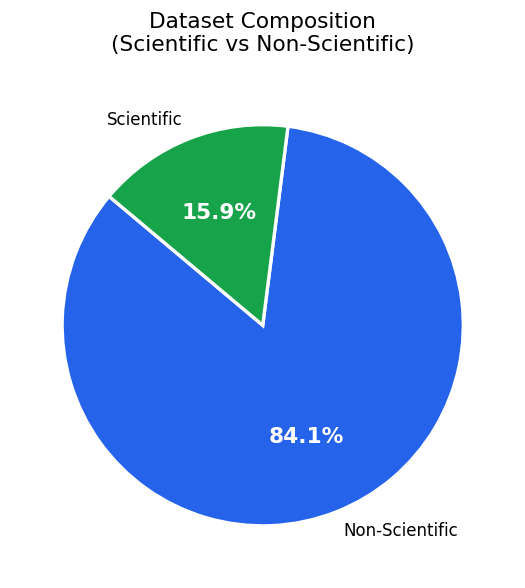

source_type
Non-Scientific    201
Scientific         38


In [28]:
# Cell 4 - Overall composition
counts = df['source_type'].value_counts()
fig,ax = plt.subplots(figsize=(5,5))
wedges,texts,autos = ax.pie(counts,labels=counts.index,autopct='%1.1f%%',
    colors=[BLUE,GREEN],startangle=140,wedgeprops=dict(edgecolor='white',linewidth=2))
for a in autos: a.set_fontsize(13);a.set_color('white');a.set_fontweight('bold')
ax.set_title('Dataset Composition\n(Scientific vs Non-Scientific)',fontsize=13,pad=14)
plt.tight_layout();savefig('fig01_composition.png');plt.show()
print(counts.to_string())

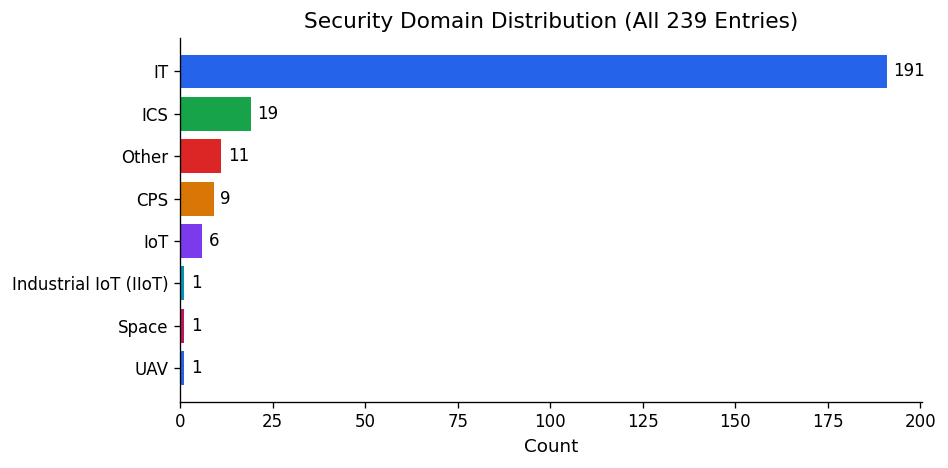

domain
IT                       191
ICS                       19
Other                     11
CPS                        9
IoT                        6
Industrial IoT (IIoT)      1
Space                      1
UAV                        1


In [29]:
# Cell 5 - Domain distribution (all entries)
dc = df['domain'].value_counts()
fig,ax = plt.subplots(figsize=(8,4))
bars = ax.barh(dc.index,dc.values,color=PALETTE[:len(dc)])
ax.bar_label(bars,padding=4,fontsize=10)
ax.set_xlabel('Count',fontsize=11)
ax.set_title('Security Domain Distribution (All 239 Entries)',fontsize=13)
ax.invert_yaxis();plt.tight_layout();savefig('fig02_domain_all.png');plt.show()
print(dc.to_string())

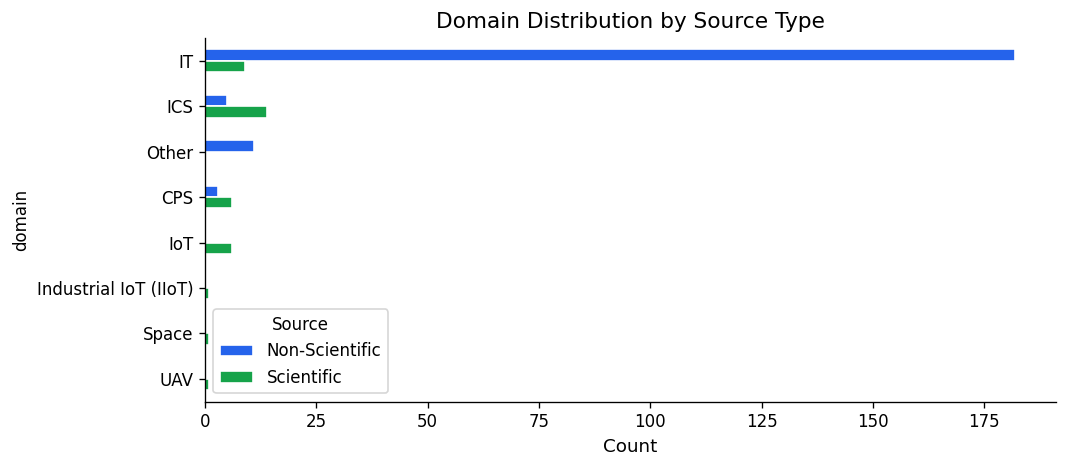

source_type            Non-Scientific  Scientific
domain                                           
IT                                182           9
ICS                                 5          14
Other                              11           0
CPS                                 3           6
IoT                                 0           6
Industrial IoT (IIoT)               0           1
Space                               0           1
UAV                                 0           1


In [30]:
# Cell 6 - Domain by source type
dcross = df.groupby(['domain','source_type']).size().unstack(fill_value=0).reindex(dc.index)
fig,ax = plt.subplots(figsize=(9,4))
dcross.plot(kind='barh',ax=ax,color=[BLUE,GREEN],edgecolor='white')
ax.set_xlabel('Count',fontsize=11);ax.set_title('Domain Distribution by Source Type',fontsize=13)
ax.invert_yaxis();ax.legend(title='Source',fontsize=10)
plt.tight_layout();savefig('fig03_domain_by_source.png');plt.show()
print(dcross.to_string())

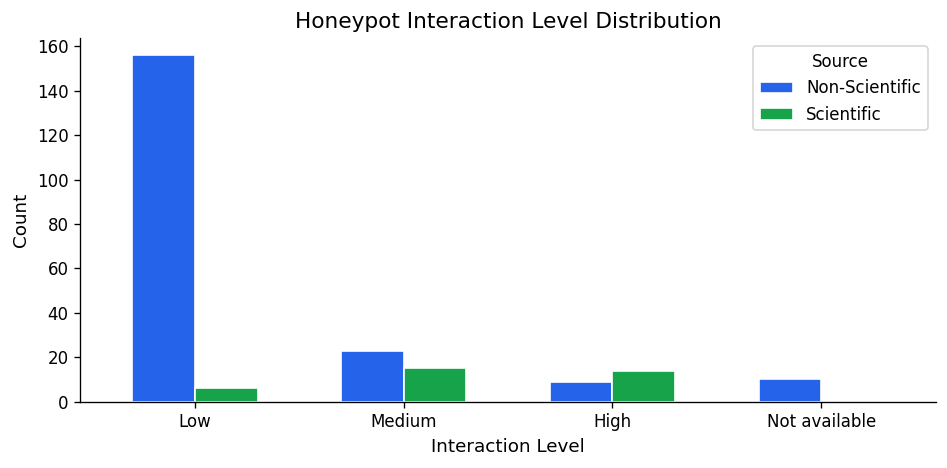

source_type        Non-Scientific  Scientific
interaction_level                            
Low                           156           6
Medium                         23          15
High                            9          14
Not available                  10           0


In [31]:
# Cell 7 - Interaction level distribution
order=['Low','Medium','High','Not available']
ic = df.groupby(['interaction_level','source_type']).size().unstack(fill_value=0)
ic = ic.reindex([o for o in order if o in ic.index])
fig,ax = plt.subplots(figsize=(8,4))
ic.plot(kind='bar',ax=ax,color=[BLUE,GREEN],edgecolor='white',width=0.6)
ax.set_xlabel('Interaction Level',fontsize=11);ax.set_ylabel('Count',fontsize=11)
ax.set_title('Honeypot Interaction Level Distribution',fontsize=13)
ax.set_xticklabels(ic.index,rotation=0);ax.legend(title='Source',fontsize=10)
plt.tight_layout();savefig('fig04_interaction_level.png');plt.show()
print(ic.to_string())

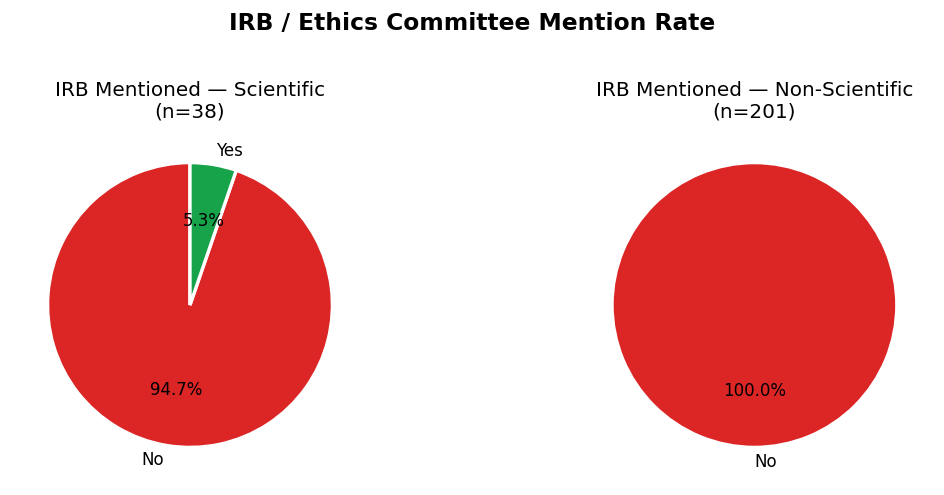

source_type    Non-Scientific  Scientific
irb_mentioned                            
No                        201          36
Yes                         0           2


In [32]:
# Cell 8 - IRB mention rate
fig,axes = plt.subplots(1,2,figsize=(10,4))
for ax,src in zip(axes,['Scientific','Non-Scientific']):
    s = df[df['source_type']==src]['irb_mentioned'].value_counts()
    clrs=[RED if v=='No' else GREEN if v=='Yes' else ORANGE for v in s.index]
    ax.pie(s,labels=s.index,autopct='%1.1f%%',colors=clrs,
           wedgeprops=dict(edgecolor='white',linewidth=2),startangle=90)
    ax.set_title(f'IRB Mentioned — {src}\n(n={len(df[df["source_type"]==src])})',fontsize=12)
plt.suptitle('IRB / Ethics Committee Mention Rate',fontsize=14,y=1.02,fontweight='bold')
plt.tight_layout();savefig('fig05_irb_rate.png');plt.show()
print(df.groupby(['irb_mentioned','source_type']).size().unstack(fill_value=0).to_string())

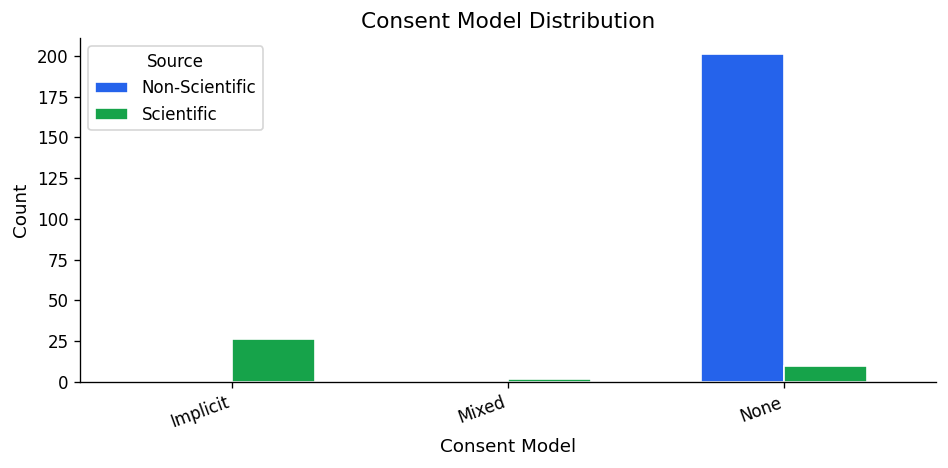

source_type    Non-Scientific  Scientific
consent_model                            
Implicit                    0          26
Mixed                       0           2
None                      201          10


In [33]:
# Cell 9 - Consent model
cc = df.groupby(['consent_model','source_type']).size().unstack(fill_value=0)
fig,ax = plt.subplots(figsize=(8,4))
cc.plot(kind='bar',ax=ax,color=[BLUE,GREEN],edgecolor='white',width=0.6)
ax.set_xlabel('Consent Model',fontsize=11);ax.set_ylabel('Count',fontsize=11)
ax.set_title('Consent Model Distribution',fontsize=13)
ax.set_xticklabels(cc.index,rotation=20,ha='right');ax.legend(title='Source',fontsize=10)
plt.tight_layout();savefig('fig06_consent_model.png');plt.show()
print(cc.to_string())

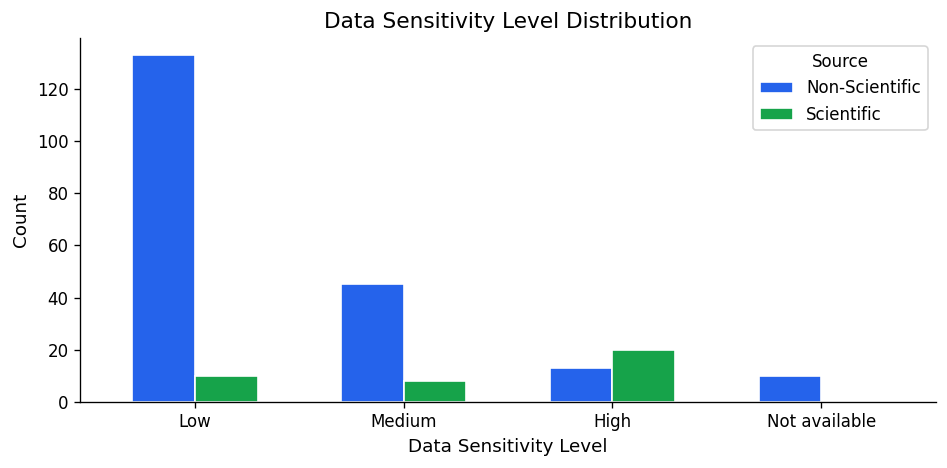

source_type       Non-Scientific  Scientific
data_sensitivity                            
Low                          133          10
Medium                        45           8
High                          13          20
Not available                 10           0


In [34]:
# Cell 10 - Data sensitivity
so=['Low','Medium','High','Not available']
sc2=df.groupby(['data_sensitivity','source_type']).size().unstack(fill_value=0)
sc2=sc2.reindex([s for s in so if s in sc2.index])
fig,ax=plt.subplots(figsize=(8,4))
sc2.plot(kind='bar',ax=ax,color=[BLUE,GREEN],edgecolor='white',width=0.6)
ax.set_xlabel('Data Sensitivity Level',fontsize=11);ax.set_ylabel('Count',fontsize=11)
ax.set_title('Data Sensitivity Level Distribution',fontsize=13)
ax.set_xticklabels(sc2.index,rotation=0);ax.legend(title='Source',fontsize=10)
plt.tight_layout();savefig('fig07_data_sensitivity.png');plt.show()
print(sc2.to_string())

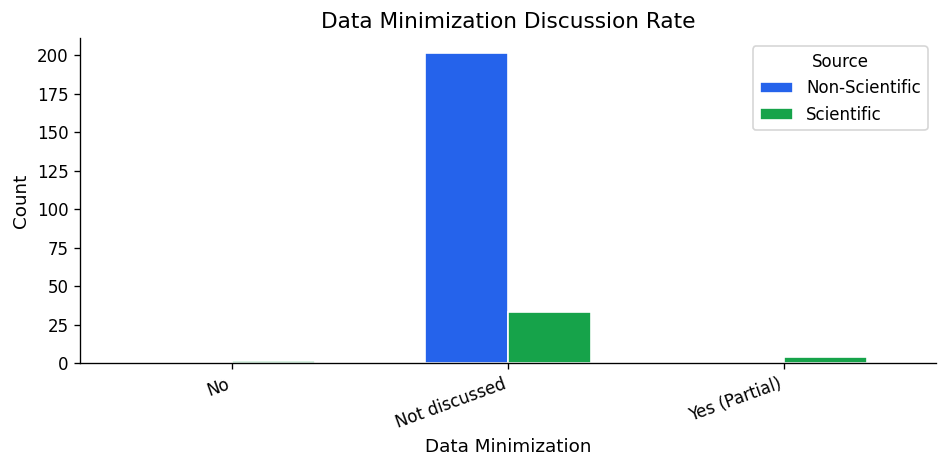

source_type        Non-Scientific  Scientific
data_minimization                            
No                              0           1
Not discussed                 201          33
Yes (Partial)                   0           4


In [35]:
# Cell 11 - Data minimization
dm=df.groupby(['data_minimization','source_type']).size().unstack(fill_value=0)
fig,ax=plt.subplots(figsize=(8,4))
dm.plot(kind='bar',ax=ax,color=[BLUE,GREEN],edgecolor='white',width=0.6)
ax.set_xlabel('Data Minimization',fontsize=11);ax.set_ylabel('Count',fontsize=11)
ax.set_title('Data Minimization Discussion Rate',fontsize=13)
ax.set_xticklabels(dm.index,rotation=20,ha='right');ax.legend(title='Source',fontsize=10)
plt.tight_layout();savefig('fig08_data_minimization.png');plt.show()
print(dm.to_string())

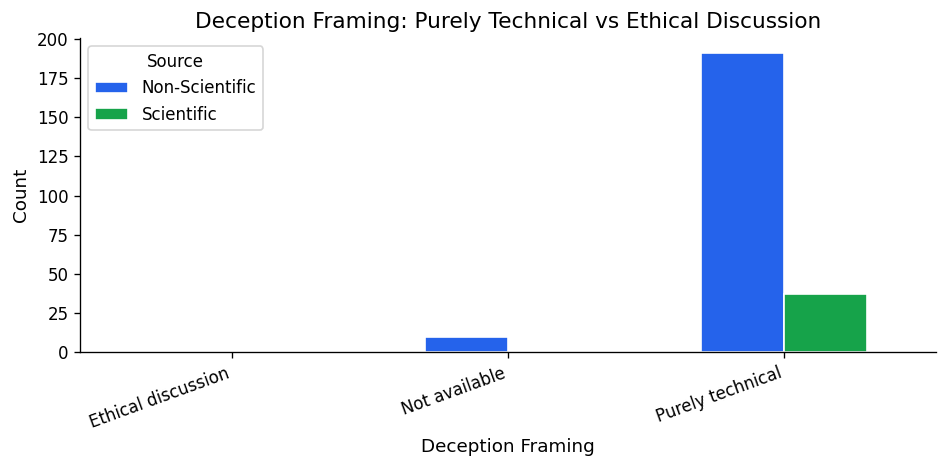

source_type         Non-Scientific  Scientific
deception_framing                             
Ethical discussion               0           1
Not available                   10           0
Purely technical               191          37


In [36]:
# Cell 12 - Deception framing
dec=df.groupby(['deception_framing','source_type']).size().unstack(fill_value=0)
fig,ax=plt.subplots(figsize=(8,4))
dec.plot(kind='bar',ax=ax,color=[BLUE,GREEN],edgecolor='white',width=0.6)
ax.set_xlabel('Deception Framing',fontsize=11);ax.set_ylabel('Count',fontsize=11)
ax.set_title('Deception Framing: Purely Technical vs Ethical Discussion',fontsize=13)
ax.set_xticklabels(dec.index,rotation=20,ha='right');ax.legend(title='Source',fontsize=10)
plt.tight_layout();savefig('fig09_deception_framing.png');plt.show()
print(dec.to_string())

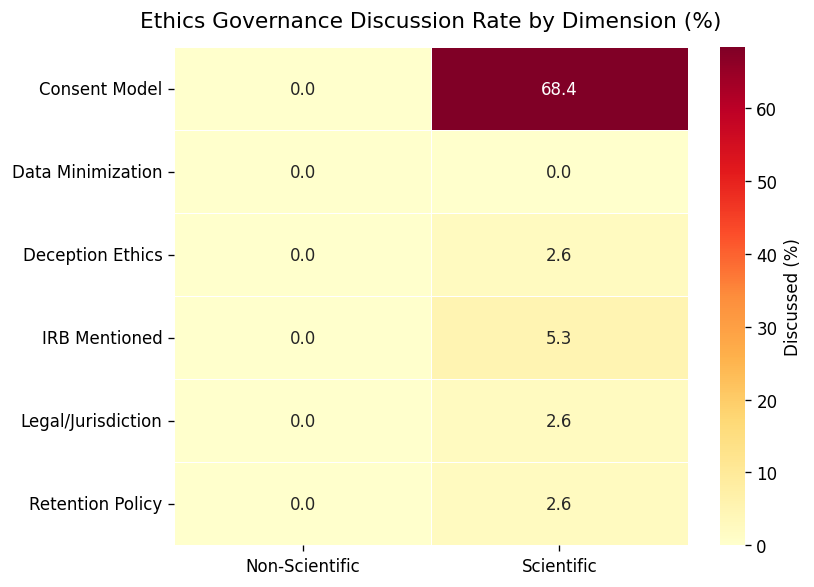

Source              Non-Scientific  Scientific
Dimension                                     
Consent Model                  0.0        68.4
Data Minimization              0.0         0.0
Deception Ethics               0.0         2.6
IRB Mentioned                  0.0         5.3
Legal/Jurisdiction             0.0         2.6
Retention Policy               0.0         2.6


In [37]:
# Cell 13 - Ethics governance heatmap (6 dimensions)
dims={
    'IRB Mentioned':     lambda r: r['irb_mentioned']=='Yes',
    'Consent Model':     lambda r: str(r['consent_model']).strip() in ('Explicit','Implicit'),
    'Data Minimization': lambda r: str(r['data_minimization']).strip()=='Yes',
    'Retention Policy':  lambda r: str(r['data_retention_policy']).strip() not in ('Not documented','Not discussed','','nan'),
    'Legal/Jurisdiction':lambda r: str(r['jurisdiction_legal']).strip() not in ('Not discussed','Not documented','','nan'),
    'Deception Ethics':  lambda r: str(r['deception_framing']).strip()=='Ethical discussion',
}
recs=[]
for src in ['Scientific','Non-Scientific']:
    sub=df[df['source_type']==src]
    for dim,fn in dims.items():
        recs.append({'Source':src,'Dimension':dim,'Rate (%)':round(sub.apply(fn,axis=1).mean()*100,1)})
hm=pd.DataFrame(recs).pivot(index='Dimension',columns='Source',values='Rate (%)')
fig,ax=plt.subplots(figsize=(7,5))
sns.heatmap(hm,annot=True,fmt='.1f',cmap='YlOrRd',ax=ax,linewidths=0.5,linecolor='white',cbar_kws={'label':'Discussed (%)'})
ax.set_title('Ethics Governance Discussion Rate by Dimension (%)',fontsize=13,pad=12)
ax.set_xlabel('');ax.set_ylabel('')
plt.tight_layout();savefig('fig10_ethics_heatmap.png');plt.show()
print(hm.to_string())

Tools with star data: 175 | Median: 48 | Mean: 358 | Max: 9300


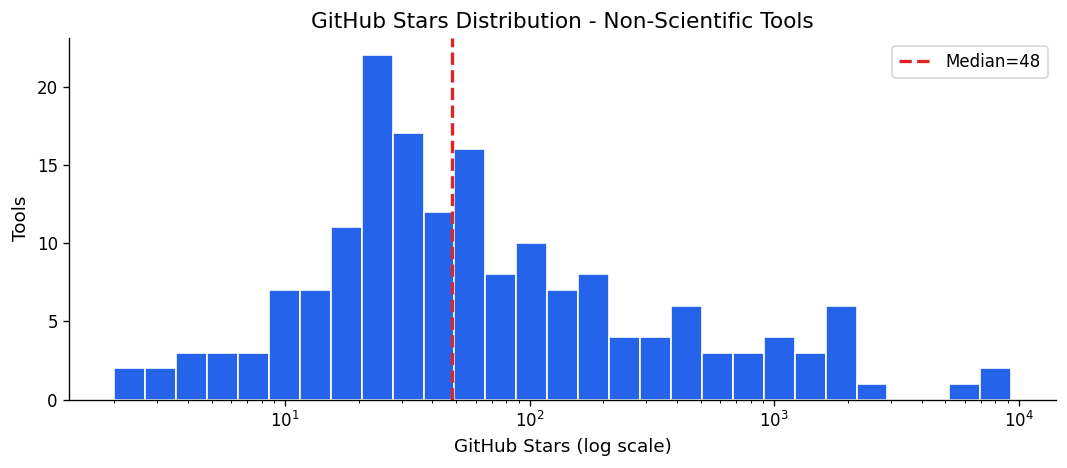

In [38]:
# Cell 14 - GitHub stars distribution (Non-Scientific only)
stars = nons['github_stars'].map(parse_stars).dropna()
stars = stars[stars > 0]
print(f'Tools with star data: {len(stars)} | Median: {stars.median():.0f} | Mean: {stars.mean():.0f} | Max: {stars.max():.0f}')
fig, ax = plt.subplots(figsize=(9,4))
# Log-scale x-axis so the full range (2 to 9,300+) is visible without cropping
import numpy as np
bins = np.logspace(np.log10(max(stars.min(),1)), np.log10(stars.max()), 30)
ax.hist(stars, bins=bins, color=BLUE, edgecolor='white')
ax.set_xscale('log')
ax.axvline(stars.median(), color=RED, linestyle='--', linewidth=2, label=f'Median={stars.median():.0f}')
ax.set_xlabel('GitHub Stars (log scale)', fontsize=11); ax.set_ylabel('Tools', fontsize=11)
ax.set_title('GitHub Stars Distribution - Non-Scientific Tools', fontsize=13)
ax.legend(fontsize=10); plt.tight_layout(); savefig('fig11_github_stars.png'); plt.show()

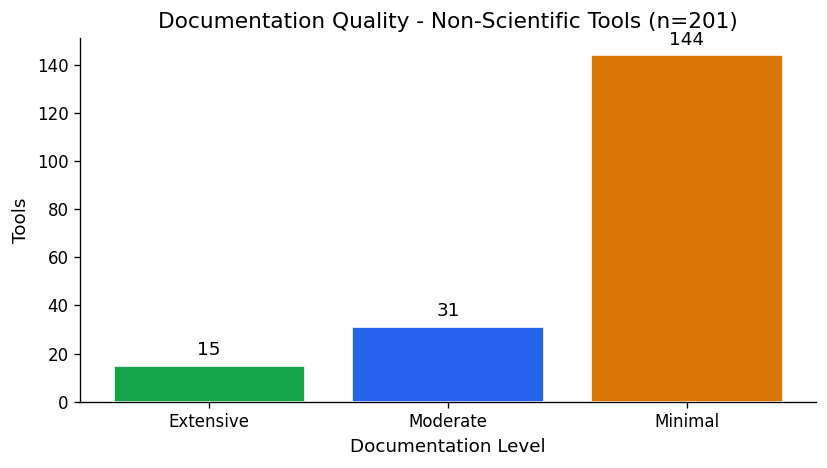

doc_level
Extensive     15
Moderate      31
Minimal      144


In [39]:
# Cell 15 - Documentation quality (Non-Scientific)
dord=['Extensive','Moderate','Minimal','None']
dcnt=nons['doc_level'].value_counts().reindex([d for d in dord if d in nons['doc_level'].value_counts().index])
fig,ax=plt.subplots(figsize=(7,4))
bars=ax.bar(dcnt.index,dcnt.values,color=[GREEN,BLUE,ORANGE,RED][:len(dcnt)],edgecolor='white')
ax.bar_label(bars,padding=4,fontsize=11)
ax.set_xlabel('Documentation Level',fontsize=11);ax.set_ylabel('Tools',fontsize=11)
ax.set_title('Documentation Quality - Non-Scientific Tools (n=201)',fontsize=13)
plt.tight_layout();savefig('fig12_doc_quality.png');plt.show()
print(dcnt.to_string())

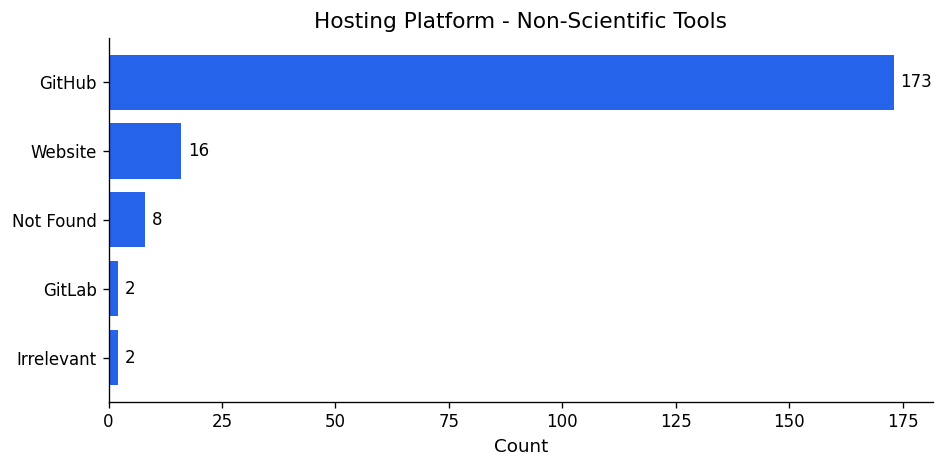

platform
GitHub        173
Website        16
Not Found       8
GitLab          2
Irrelevant      2


In [40]:
# Cell 16 - Platform breakdown (Non-Scientific)
pc=nons['platform'].value_counts()
fig,ax=plt.subplots(figsize=(8,4))
bars=ax.barh(pc.index,pc.values,color=BLUE)
ax.bar_label(bars,padding=4,fontsize=10)
ax.set_xlabel('Count',fontsize=11);ax.set_title('Hosting Platform - Non-Scientific Tools',fontsize=13)
ax.invert_yaxis();plt.tight_layout();savefig('fig13_platforms.png');plt.show()
print(pc.to_string())

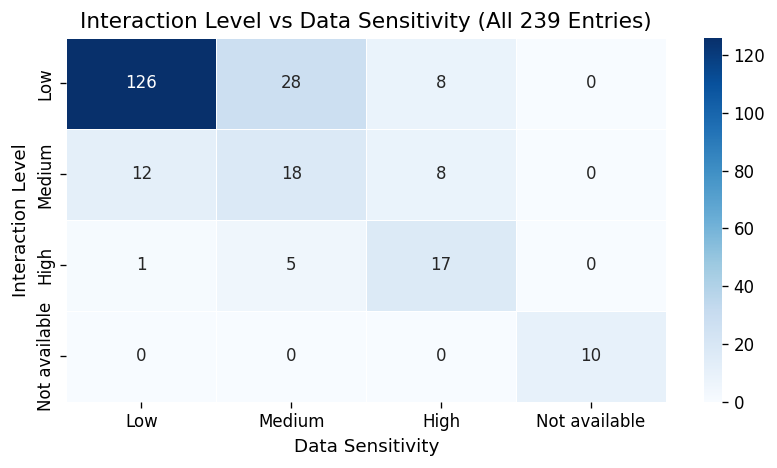

data_sensitivity   Low  Medium  High  Not available
interaction_level                                  
Low                126      28     8              0
Medium              12      18     8              0
High                 1       5    17              0
Not available        0       0     0             10


In [41]:
# Cell 17 - Interaction level × Data sensitivity heatmap
ct=pd.crosstab(df['interaction_level'],df['data_sensitivity'])
ct=ct.reindex(['Low','Medium','High','Not available'])
ct=ct[[c for c in ['Low','Medium','High','Not available'] if c in ct.columns]]
fig,ax=plt.subplots(figsize=(7,4))
sns.heatmap(ct,annot=True,fmt='d',cmap='Blues',ax=ax,linewidths=0.5,linecolor='white')
ax.set_title('Interaction Level vs Data Sensitivity (All 239 Entries)',fontsize=13)
ax.set_xlabel('Data Sensitivity',fontsize=11);ax.set_ylabel('Interaction Level',fontsize=11)
plt.tight_layout();savefig('fig14_interaction_vs_sensitivity.png');plt.show()
print(ct.to_string())

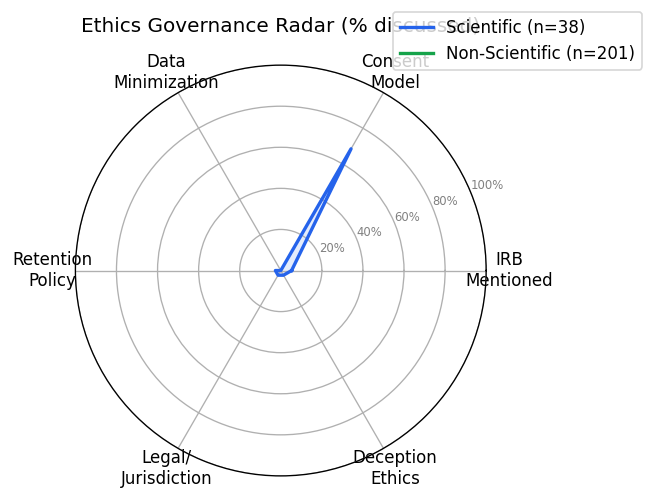

Scientific: {'IRB Mentioned': np.float64(5.3), 'Consent Model': np.float64(68.4), 'Data Minimization': np.float64(0.0), 'Retention Policy': np.float64(2.6), 'Legal/ Jurisdiction': np.float64(2.6), 'Deception Ethics': np.float64(2.6)}
Non-Scientific: {'IRB Mentioned': np.float64(0.0), 'Consent Model': np.float64(0.0), 'Data Minimization': np.float64(0.0), 'Retention Policy': np.float64(0.0), 'Legal/ Jurisdiction': np.float64(0.0), 'Deception Ethics': np.float64(0.0)}


In [42]:
# Cell 18 - Ethics governance radar chart
labels=['IRB\nMentioned','Consent\nModel','Data\nMinimization','Retention\nPolicy','Legal/\nJurisdiction','Deception\nEthics']
def gov_rates(sub):
    n=len(sub)
    return [
        (sub['irb_mentioned']=='Yes').sum()/n*100,
        sub['consent_model'].isin(['Explicit','Implicit']).sum()/n*100,
        (sub['data_minimization']=='Yes').sum()/n*100,
        (~sub['data_retention_policy'].fillna('').str.strip().isin(['Not documented','Not discussed','','nan'])).sum()/n*100,
        (~sub['jurisdiction_legal'].fillna('').str.strip().isin(['Not discussed','Not documented','','nan'])).sum()/n*100,
        (sub['deception_framing']=='Ethical discussion').sum()/n*100,
    ]
sr=gov_rates(sci); nr=gov_rates(nons)
N=len(labels); angles=[n/N*2*np.pi for n in range(N)]+[0]
fig,ax=plt.subplots(figsize=(6,6),subplot_kw=dict(polar=True))
for vals,color,lbl in [(sr,BLUE,f'Scientific (n={len(sci)})'),(nr,GREEN,f'Non-Scientific (n={len(nons)})')]:
    v=vals+vals[:1]; ax.plot(angles,v,color=color,linewidth=2,label=lbl); ax.fill(angles,v,color=color,alpha=0.12)
ax.set_xticks(angles[:-1]); ax.set_xticklabels(labels,fontsize=10)
ax.set_ylim(0,100); ax.set_yticks([20,40,60,80,100])
ax.set_yticklabels(['20%','40%','60%','80%','100%'],fontsize=7,color='grey')
ax.set_title('Ethics Governance Radar (% discussed)',fontsize=12,pad=20)
ax.legend(loc='upper right',bbox_to_anchor=(1.4,1.15),fontsize=10)
plt.tight_layout();savefig('fig15_ethics_radar.png');plt.show()
print('Scientific:',{l.replace(chr(10),' '):round(r,1) for l,r in zip(labels,sr)})
print('Non-Scientific:',{l.replace(chr(10),' '):round(r,1) for l,r in zip(labels,nr)})

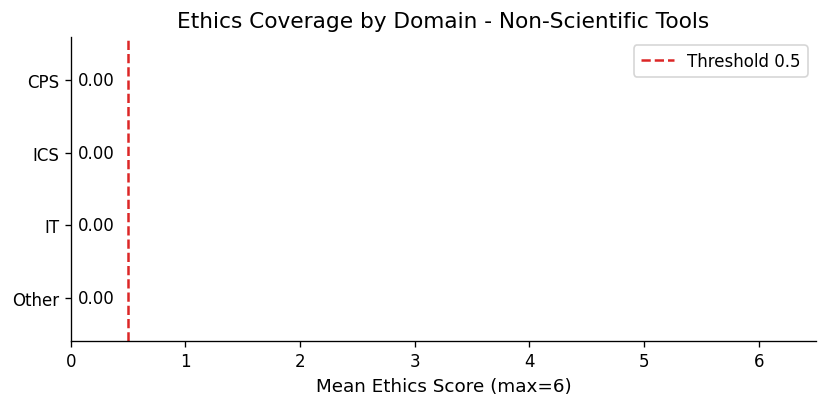

        Mean Score (max=6)  Count
domain                           
CPS                    0.0      3
ICS                    0.0      5
IT                     0.0    182
Other                  0.0     11


In [43]:
# Cell 19 - Ethics coverage score by domain (Non-Scientific)
def eth(row):
    return sum([int(str(row['irb_mentioned']).strip()=='Yes'),
                int(str(row['consent_model']).strip() in ('Explicit','Implicit')),
                int(str(row['data_minimization']).strip()=='Yes'),
                int(str(row['data_retention_policy']).strip() not in ('Not documented','Not discussed','','nan')),
                int(str(row['jurisdiction_legal']).strip() not in ('Not discussed','Not documented','','nan')),
                int(str(row['deception_framing']).strip()=='Ethical discussion')])
nons['ethics_score']=nons.apply(eth,axis=1)
sbd=nons.groupby('domain')['ethics_score'].agg(['mean','count']).sort_values('mean',ascending=False)
sbd.columns=['Mean Score (max=6)','Count']
fig,ax=plt.subplots(figsize=(7,3.5))
bars=ax.barh(sbd.index,sbd['Mean Score (max=6)'],color=BLUE)
ax.bar_label(bars,fmt='%.2f',padding=4,fontsize=10); ax.set_xlim(0,6.5)
ax.axvline(0.5,color=RED,linestyle='--',linewidth=1.5,label='Threshold 0.5')
ax.set_xlabel('Mean Ethics Score (max=6)',fontsize=11)
ax.set_title('Ethics Coverage by Domain - Non-Scientific Tools',fontsize=13)
ax.legend(fontsize=10); ax.invert_yaxis()
plt.tight_layout();savefig('fig16_ethics_by_domain.png');plt.show()
print(sbd.to_string())

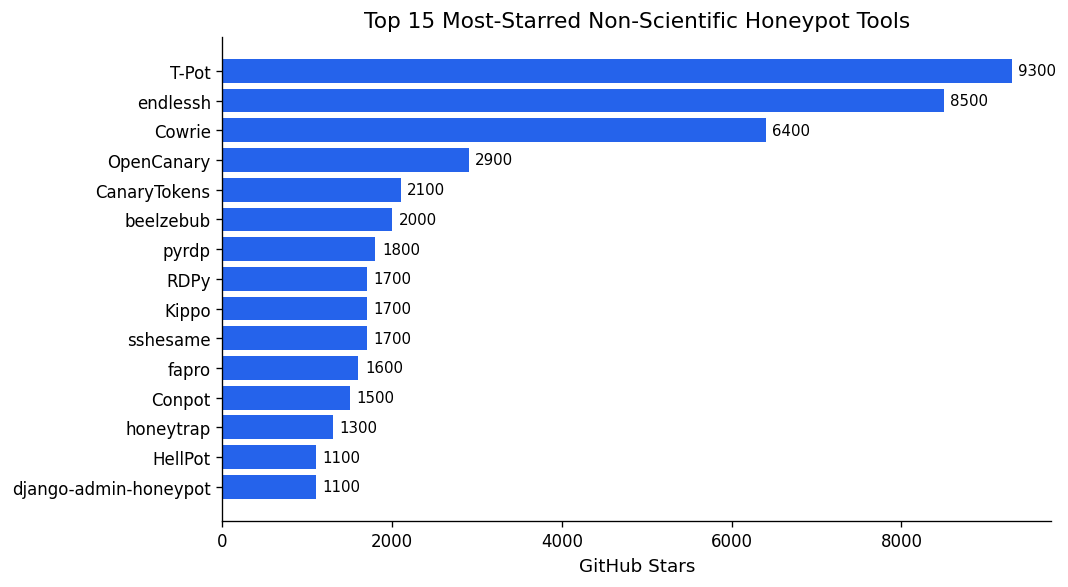

,identifier,github_stars,domain,interaction_level
0,T-Pot,9300.0,IT,Low
1,endlessh,8500.0,IT,Low
2,Cowrie,6400.0,IT,Medium
3,OpenCanary,2900.0,IT,Low
4,CanaryTokens,2100.0,IT,Low
5,beelzebub,2000.0,IT,Medium
6,pyrdp,1800.0,IT,High
7,RDPy,1700.0,IT,Medium
8,Kippo,1700.0,IT,Medium
9,sshesame,1700.0,IT,Low


In [44]:
# Cell 20 - Top 15 most-starred tools
ns2 = nons.copy(); ns2['github_stars'] = ns2['github_stars'].map(parse_stars)
top15 = ns2.nlargest(15, 'github_stars')[['identifier','github_stars','domain','interaction_level']]
fig, ax = plt.subplots(figsize=(9,5))
bars = ax.barh(top15['identifier'], top15['github_stars'], color=BLUE)
ax.bar_label(bars, fmt='%.0f', padding=4, fontsize=9)
ax.set_xlabel('GitHub Stars', fontsize=11); ax.set_title('Top 15 Most-Starred Non-Scientific Honeypot Tools', fontsize=13)
ax.invert_yaxis(); plt.tight_layout(); savefig('fig17_top15_stars.png'); plt.show()
display(top15.reset_index(drop=True))

ICS/CPS/Space: 29 | Scientific: 21 | Non-Scientific: 8


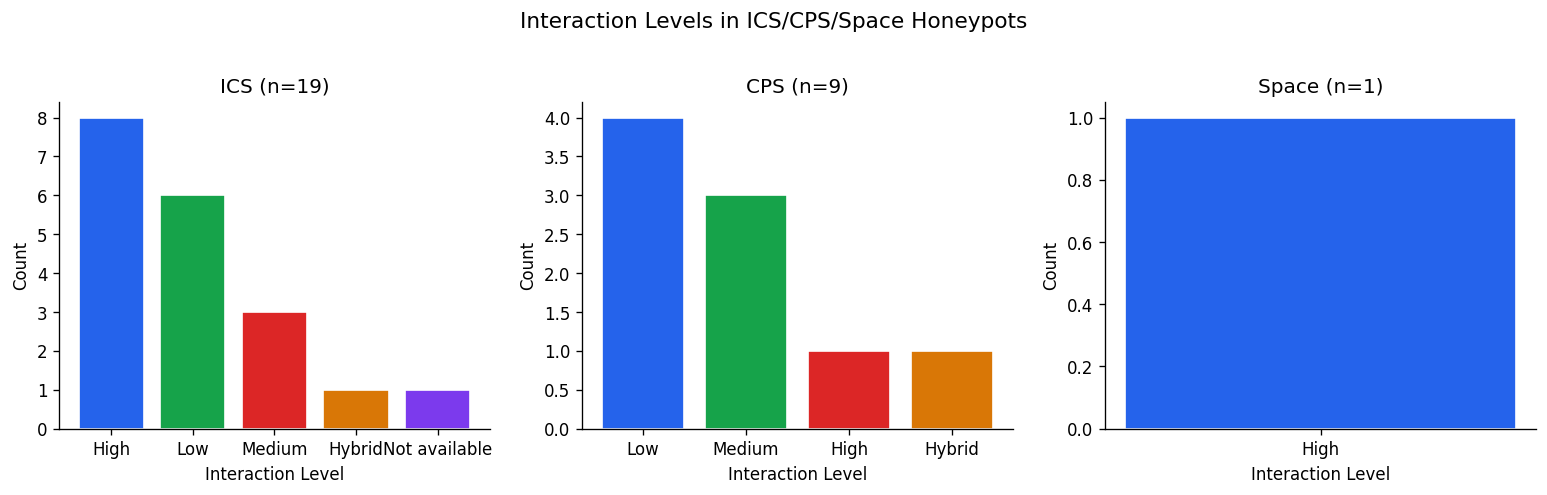

IRB by source for ICS/CPS/Space:
irb_mentioned   No  Yes
source_type            
Non-Scientific   8    0
Scientific      19    2


In [45]:
# Cell 21 - ICS / CPS / Space deep-dive
cps=df[df['domain'].isin(['ICS','CPS','Space'])].copy()
print(f'ICS/CPS/Space: {len(cps)} | Scientific: {(cps["source_type"]=="Scientific").sum()} | Non-Scientific: {(cps["source_type"]=="Non-Scientific").sum()}')
domains_present=[d for d in ['ICS','CPS','Space'] if d in cps['domain'].unique()]
fig,axes=plt.subplots(1,len(domains_present),figsize=(13,4))
if len(domains_present)==1: axes=[axes]
for ax,dom in zip(axes,domains_present):
    ic2=cps[cps['domain']==dom]['interaction_level'].value_counts()
    ax.bar(ic2.index,ic2.values,color=PALETTE[:len(ic2)],edgecolor='white')
    ax.set_title(f'{dom} (n={len(cps[cps["domain"]==dom])})',fontsize=12)
    ax.set_xlabel('Interaction Level',fontsize=10); ax.set_ylabel('Count',fontsize=10)
plt.suptitle('Interaction Levels in ICS/CPS/Space Honeypots',fontsize=13,y=1.02)
plt.tight_layout();savefig('fig18_cps_ics_space.png');plt.show()
print('IRB by source for ICS/CPS/Space:')
print(cps.groupby(['source_type','irb_mentioned']).size().unstack(fill_value=0).to_string())

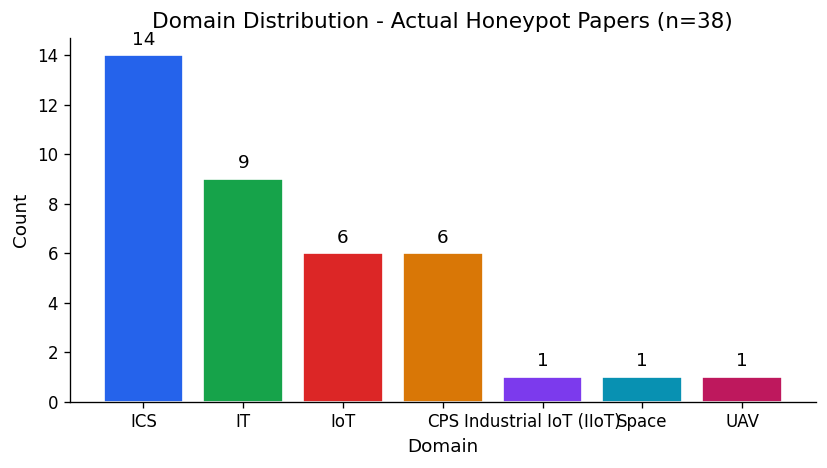

domain
ICS                      14
IT                        9
IoT                       6
CPS                       6
Industrial IoT (IIoT)     1
Space                     1
UAV                       1


In [46]:
# Cell 22 - Scientific papers domain distribution
sd=sci['domain'].value_counts()
fig,ax=plt.subplots(figsize=(7,4))
bars=ax.bar(sd.index,sd.values,color=PALETTE[:len(sd)],edgecolor='white')
ax.bar_label(bars,padding=4,fontsize=11)
ax.set_xlabel('Domain',fontsize=11); ax.set_ylabel('Count',fontsize=11)
ax.set_title(f'Domain Distribution - Actual Honeypot Papers (n={len(sci)})',fontsize=13)
plt.tight_layout();savefig('fig19_sci_domain.png');plt.show()
print(sd.to_string())

In [47]:
# Cell 23 - Summary statistics table
rows=[]
for src in ['Scientific','Non-Scientific','All']:
    s=df if src=='All' else df[df['source_type']==src]; n=len(s)
    rows.append({'Source':src,'N':n,
        'IRB Yes (%)':f"{(s['irb_mentioned']=='Yes').mean()*100:.1f}",
        'Consent Expl/Impl (%)':f"{s['consent_model'].isin(['Explicit','Implicit']).mean()*100:.1f}",
        'Data Min Yes (%)':f"{(s['data_minimization']=='Yes').mean()*100:.1f}",
        'Deception Ethics (%)':f"{(s['deception_framing']=='Ethical discussion').mean()*100:.1f}",
        'High Sensitivity (%)':f"{(s['data_sensitivity']=='High').mean()*100:.1f}",
        'High Interaction (%)':f"{(s['interaction_level']=='High').mean()*100:.1f}"})
print('=== SUMMARY STATISTICS ===')
display(pd.DataFrame(rows).set_index('Source'))

=== SUMMARY STATISTICS ===


,N,IRB Yes (%),Consent Expl/Impl (%),Data Min Yes (%),Deception Ethics (%),High Sensitivity (%),High Interaction (%)
Source,,,,,,,
Scientific,38,5.3,68.4,0.0,2.6,52.6,36.8
Non-Scientific,201,0.0,0.0,0.0,0.0,6.5,4.5
All,239,0.8,10.9,0.0,0.4,13.8,9.6


In [48]:
# Cell 24 - Key findings
print('='*65)
print('KEY FINDINGS — HONEYPOT ETHICS LITERATURE REVIEW')
print('='*65)
print(f"""
Dataset:
  Total entries              : {len(df)}
  Scientific (actual HP only): {len(sci)}
  Non-Scientific tools       : {len(nons)}

IRB / Ethics Committee:
  Papers with IRB : {(sci['irb_mentioned']=='Yes').sum()}/{len(sci)} ({(sci['irb_mentioned']=='Yes').mean()*100:.1f}%)
  Tools with IRB  : {(nons['irb_mentioned']=='Yes').sum()}/{len(nons)} ({(nons['irb_mentioned']=='Yes').mean()*100:.1f}%)

Consent Model (Explicit or Implicit):
  Papers: {sci['consent_model'].isin(['Explicit','Implicit']).sum()}/{len(sci)} ({sci['consent_model'].isin(['Explicit','Implicit']).mean()*100:.1f}%)
  Tools : {nons['consent_model'].isin(['Explicit','Implicit']).sum()}/{len(nons)} ({nons['consent_model'].isin(['Explicit','Implicit']).mean()*100:.1f}%)

High Data Sensitivity:
  Papers: {(sci['data_sensitivity']=='High').sum()}/{len(sci)} ({(sci['data_sensitivity']=='High').mean()*100:.1f}%)
  Tools : {(nons['data_sensitivity']=='High').sum()}/{len(nons)} ({(nons['data_sensitivity']=='High').mean()*100:.1f}%)

Deception Ethics Discussion:
  Papers: {(sci['deception_framing']=='Ethical discussion').sum()}/{len(sci)} ({(sci['deception_framing']=='Ethical discussion').mean()*100:.1f}%)
  Tools : {(nons['deception_framing']=='Ethical discussion').sum()}/{len(nons)} ({(nons['deception_framing']=='Ethical discussion').mean()*100:.1f}%)

Domain Distribution:
{df['domain'].value_counts().to_string()}

Interaction Levels:
{df['interaction_level'].value_counts().to_string()}
""")

KEY FINDINGS — HONEYPOT ETHICS LITERATURE REVIEW

Dataset:
  Total entries              : 239
  Scientific (actual HP only): 38
  Non-Scientific tools       : 201

IRB / Ethics Committee:
  Papers with IRB : 2/38 (5.3%)
  Tools with IRB  : 0/201 (0.0%)

Consent Model (Explicit or Implicit):
  Papers: 26/38 (68.4%)
  Tools : 0/201 (0.0%)

High Data Sensitivity:
  Papers: 20/38 (52.6%)
  Tools : 13/201 (6.5%)

Deception Ethics Discussion:
  Papers: 1/38 (2.6%)
  Tools : 0/201 (0.0%)

Domain Distribution:
domain
IT                       191
ICS                       19
Other                     11
CPS                        9
IoT                        6
Industrial IoT (IIoT)      1
Space                      1
UAV                        1

Interaction Levels:
interaction_level
Low               162
Medium             38
High               23
Not available      10
Hybrid              3
Not applicable      3

